# Задача: Text classification

Научиться работать с текстовыми данными и построить модель классификации текстов.

## 1. Загрузка датасета

In [1]:
from pathlib import Path

import pandas as pd

data_dir = Path("data")

train_df = pd.read_csv(data_dir / "train.csv")
test_df = pd.read_csv(data_dir / "test.csv")

print("Train", train_df.shape)
print("Kaggle test", test_df.shape)

display(train_df.head())

Train (7613, 5)
Kaggle test (3263, 4)


,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


В `train.csv` 7 613 размеченных твитов. В `test.csv` 3 263 твита без столбца `target`. Для сравнения моделей выделяем валидацию из размеченной части.

## 2. EDA


### 2.1. Баланс классов и пропуски


In [2]:
class_counts = train_df["target"].value_counts(dropna=False).sort_index()
display(pd.DataFrame({
    "count": class_counts,
    "share_pct": (class_counts / len(train_df) * 100).round(2),
}))

missing_counts = train_df.isna().sum()
display(pd.DataFrame({
    "missing": missing_counts,
    "share_pct": (missing_counts / len(train_df) * 100).round(2),
}))

,count,share_pct
target,,
0,4342,57.03
1,3271,42.97


,missing,share_pct
id,0,0.00
keyword,61,0.80
location,2533,33.27
text,0,0.00
target,0,0.00


### 2.2. Длина твитов


In [3]:
tweet_lengths = pd.DataFrame({
    "chars": train_df["text"].str.len(),
    "words": train_df["text"].str.split().str.len(),
})

display(tweet_lengths.describe(percentiles=[0.5, 0.95]).round(1))
display(tweet_lengths.groupby(train_df["target"]).median())

,chars,words
count,7613.0,7613.0
mean,101.0,14.9
std,33.8,5.7
min,7.0,1.0
50%,107.0,15.0
95%,140.0,24.0
max,157.0,31.0


,chars,words
target,,
0,101.0,15.0
1,115.0,15.0


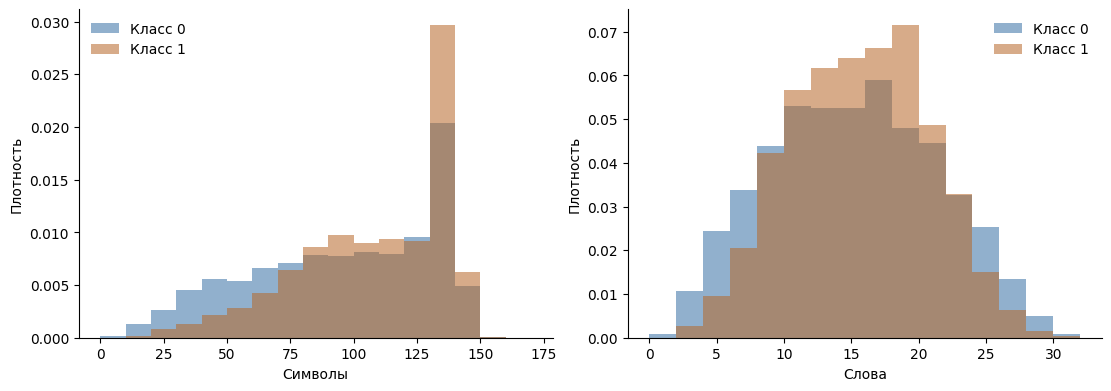

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")

for label, color in [(0, "#386fa4"), (1, "#b76728")]:
    lengths = tweet_lengths.loc[train_df["target"] == label]
    axes[0].hist(
        lengths["chars"], bins=range(0, 171, 10), density=True,
        alpha=0.55, color=color, label=f"Класс {label}",
    )
    axes[1].hist(
        lengths["words"], bins=range(0, 34, 2), density=True,
        alpha=0.55, color=color, label=f"Класс {label}",
    )

for ax, label in zip(axes, ["Символы", "Слова"]):
    ax.set_xlabel(label)
    ax.set_ylabel("Плотность")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)

plt.show()

### Выводы по балансу, пропускам и длине твитов

- Класс `0` составляет 57,03% выборки (4 342 твита), класс `1` — 42,97% (3 271 твит). Перевес класса `0` небольшой. При разбиении сохраним пропорции классов.
- Поля `text` и `target` заполнены во всех строках. В `keyword` пропущено 0,80% значений, в `location` — 33,27%. В первой модели используем `text` как входной признак.
- Медианная длина твита — 107 символов и 15 слов. 95-й перцентиль составляет 140 символов по длине и 24 слова по числу слов.
- У твитов класса `1` медиана длины выше в символах (115 против 101). По числу слов медиана одинакова — 15 в обоих классах.

### 2.3. Проверка повторов текстов

In [5]:
text_stats = train_df.groupby("text")["target"].agg(
    rows="size",
    unique_targets="nunique",
)

repeated_texts = text_stats[text_stats["rows"] > 1]
conflicting_texts = repeated_texts[repeated_texts["unique_targets"] > 1]

print("Уникальных текстов с повторами:", len(repeated_texts))
print("Всего строк с такими текстами:", repeated_texts["rows"].sum())
print("Текстов с разными метками:", len(conflicting_texts))

display(conflicting_texts.sort_values("rows", ascending=False).head())

Уникальных текстов с повторами: 69
Всего строк с такими текстами: 179
Текстов с разными метками: 18


,rows,unique_targets
text,,
The Prophet (peace be upon him) said 'Save yourself from Hellfire even if it is by giving half a date in charity.',6,2
He came to a land which was engulfed in tribal war and turned it into a land of peace i.e. Madinah. #ProphetMuhammad #islam,6,2
that horrible sinking feeling when youÛªve been at home on your phone for a while and you realise its been on 3G this whole time,4,2
.POTUS #StrategicPatience is a strategy for #Genocide; refugees; IDP Internally displaced people; horror; etc. https://t.co/rqWuoy1fm4,4,2
To fight bioterrorism sir.,4,2


### 2.4. Готовим данные для моделей


In [6]:
from tweetclf.data import prepare_data

clean_df = prepare_data(train_df)
print("Строк после очистки", len(clean_df))

Строк после очистки 7485


В 179 строках встречаются 69 повторяющихся текстов. Для 18 текстов есть метки обоих классов. Исключаем все строки с такими текстами и оставляем по одному экземпляру каждого текста с согласованной меткой. После очистки остаётся 7 485 твитов.

## 3. Разбиваем данные на обучение и валидацию

In [7]:
import yaml

from tweetclf.data import make_split

with Path("configs/experiment.yaml").open(encoding="utf-8") as stream:
    config = yaml.safe_load(stream)

split = make_split(
    train_df,
    seed=config["seed"],
    group_folds=config["data"]["validation_group_folds"],
)
train_split, val_split = split.train, split.val

print("Train", len(train_split))
print("Validation", len(val_split))
display(pd.DataFrame({
    "train_pct": train_split["target"].value_counts(normalize=True).sort_index() * 100,
    "validation_pct": val_split["target"].value_counts(normalize=True).sort_index() * 100,
}).round(2))

Train 5987
Validation 1498


,train_pct,validation_pct
target,,
0,57.41,57.41
1,42.59,42.59


После нормализации ссылок, упоминаний и регистра группируем твиты с одинаковой последовательностью токенов. Используем первый фолд `StratifiedGroupKFold` из пяти. Одна группа целиком попадает в одну выборку. Все модели оцениваются на одних и тех же 1 498 твитах. Код экспериментов, команды запуска и объяснение результатов вынесены в [README](README.md). Полная таблица доступна в [metrics.csv](results/metrics.csv).